# Feature selection

In this example we will compare filtering methods, wrapper methods and embedded methods, in terms of

1. the number of features selected,

2. the resulting prediction accuracy and

3. the computation time used.

__Filtering__: Correlation of each feature with each of the response variables.

__Wrapper methods__: Forward Selection and Backward Elimination using Partial Least Squares Regression (PLSR) as the learning algorithm. The criterion to be minimised will be the cross-validated (10-fold) Mean Squared Error of prediction of the response variables.

__Embedded methods__: Ridge regression, LASSO and Elastic net.

In [26]:
# Importing modules

import pandas as pd
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
import time
import warnings
warnings.filterwarnings("ignore")


In [27]:
# Loading the data

df=sio.loadmat('circadian.mat')

# Defining the predictor matrix and the response variables 

X=df['X'][:,2800:3200]
Y=df['Y']

print(X.shape)
print(Y.shape)

# Splitting the data into training set and test set
[X_train, X_test, Y_train, Y_test] = train_test_split(
    X, Y, test_size=0.3, random_state=0)

ssc = StandardScaler()
ssc.fit(X_train)
X_train_std = ssc.transform(X_train)
X_test_std = ssc.transform(X_test)

ssc = StandardScaler()
ssc.fit(Y_train)
Y_train_std = ssc.transform(Y_train)
Y_test_std = ssc.transform(Y_test)

(200, 400)
(200, 4)


## Filtering on the correlation with the response variables

In [28]:
# Calculating correlations between each feature and the response
def calc_R(X,Y):
    R=np.empty((Y.shape[1],X.shape[1]), dtype='object')
    for j in range(0,Y.shape[1]):
        r=[]
        for i in range(0,X.shape[1]):    
            c=np.corrcoef(X[:,i],Y[:,j])[0]
            r.append(c[1])      
        R[j,:]=r
    return R

R=calc_R(X_train,Y_train)

thresholds=np.arange(0.3, 1, 0.01)

inmodelF={}
BPLSRf={}
mse=[]
pc={}
 
start = time.time()
for t in thresholds:
    inmodel=[]
    # Finding correlations which are larger than the threshold
    for i in range(0,R.shape[0]):
        r=R[i,:]
        inF=np.where(abs(r)>t)
        inmodel=np.append(inmodel,inF)
        
    inmodel=np.unique(inmodel).astype('int32')
    inmodelF[str(round(t,2))]=inmodel   
    
    # Running a PLSR regression using the selected subset of features
    pls = PLSRegression(scale=False)
    
    pls_params = {'n_components': range(0,21)} #Testing from 1 to 20 PCs
    gs_random = GridSearchCV(estimator=pls, param_grid=pls_params, cv=10)
    gs_random.fit(X_train_std[:,inmodel], Y_train_std)

    pc[str(round(t,2))]=gs_random.best_params_
    
    pls = PLSRegression(**gs_random.best_params_, scale=False)

    pls.fit(X_train_std[:,inmodel], Y_train_std)
    Y_pred_train = pls.predict(X_train_std[:,inmodel])
    Y_pred_test = pls.predict(X_test_std[:,inmodel])
    
    BPLSRf[str(round(t,2))]=pls.coef_
    mse=np.append(mse,mean_squared_error(Y_pred_test, Y_test_std))

minMSEind=mse.argmin()
mse_f=mse[minMSEind]
selected_f=inmodelF[str(round(thresholds[minMSEind],2))]
best_threshold=str(round(thresholds[minMSEind],2))

end = time.time()
time_used_f=end - start

print('Optimal threshold (%): {0:.2f}'.format(thresholds[minMSEind]))
print('MSE: {0:.4f}'.format(mse_f))
print('Number of PCs: '+str((pc[best_threshold]['n_components'])))
print('Number of features selected: '+str(len(selected_f)))
print('Elapsed time (s): {0:.2f}'.format(time_used_f))

Optimal threshold (%): 0.80
MSE: 0.2531
Number of PCs: 8
Number of features selected: 393
Elapsed time (s): 50.81


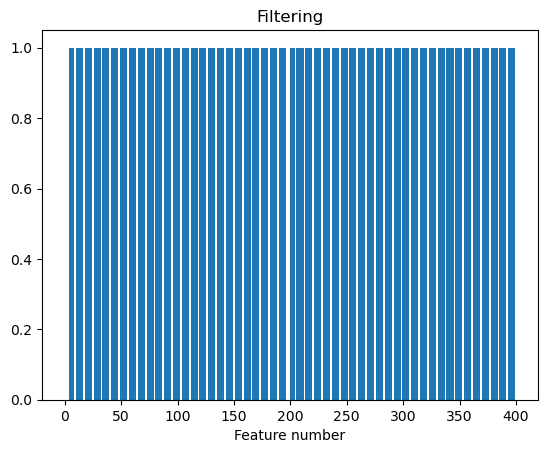

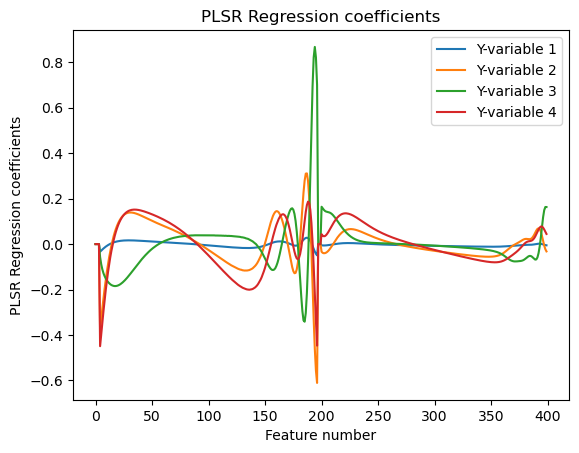

In [29]:
# Plotting the selected features
InF=np.zeros((1,X.shape[1]), dtype=int)[0]
InF[selected_f]=1

fig, ax=plt.subplots()
plt.bar(range(0,X.shape[1]),InF)
plt.title('Filtering')
plt.xlabel('Feature number')
plt.show()

# Plotting the resulting PLSR regression coefficients
B=BPLSRf[best_threshold].T

B_f=np.zeros((X.shape[1],4))

i=0
for j in selected_f: 
        B_f[j,:]=B[i,:]
        i=i+1
        
fig, ax=plt.subplots()
plt.plot(range(0,X.shape[1]),B_f)
plt.title('PLSR Regression coefficients')
ax.legend(['Y-variable 1', 'Y-variable 2', 'Y-variable 3', 'Y-variable 4'])
plt.xlabel('Feature number')
plt.ylabel('PLSR Regression coefficients')
plt.show()

## Embedded methods: Ridge regression

In [30]:
from sklearn.linear_model import Ridge

ridge=Ridge()
ridge_params = {'alpha': [1,0.1,0.01,0.001,0.0001,0]}

gs_random = GridSearchCV(estimator=ridge, param_grid=ridge_params, cv=10)

start = time.time()

gs_random.fit(X_train_std, Y_train_std)

ridge = Ridge(**gs_random.best_params_)

ridge.fit(X_train_std, Y_train_std)

B_Ridge=ridge.coef_


selected=[]
for i in range(0,Y.shape[1]):
    sel=np.where(abs(B_Ridge[i,:])>(np.mean(abs(B_Ridge[i,:]))+2*np.std(abs(B_Ridge[i,:]))))
    selected=np.append(selected,sel)   
                 
selected=np.unique(selected)
selected_Ridge = [int(i) for i in selected]

gs_random.fit(X_train_std[:,selected_Ridge], Y_train_std)

ridge = Ridge(**gs_random.best_params_)

ridge.fit(X_train_std[:,selected_Ridge], Y_train_std)
Y_pred_train = ridge.predict(X_train_std[:,selected_Ridge])
Y_pred_test = ridge.predict(X_test_std[:,selected_Ridge])

mse_Ridge=mean_squared_error(Y_pred_test, Y_test_std)

end = time.time()
time_used_Ridge=end - start


In [31]:
print('MSE: {0:.4f}'.format(mse_Ridge))
print('Number of features selected: '+str(len(selected_Ridge)))
print('Elapsed time (s): {0:.2f}'.format(time_used_Ridge))

MSE: 0.2559
Number of features selected: 34
Elapsed time (s): 0.11


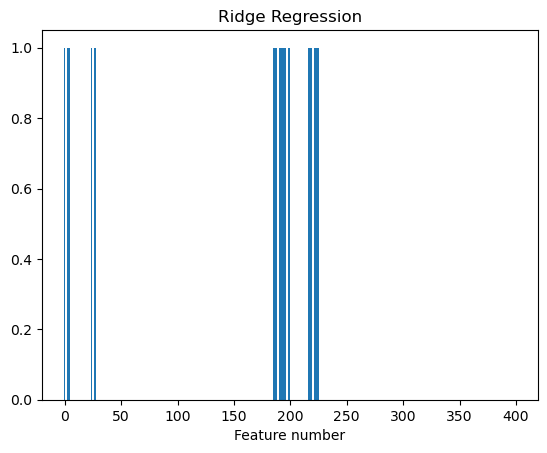

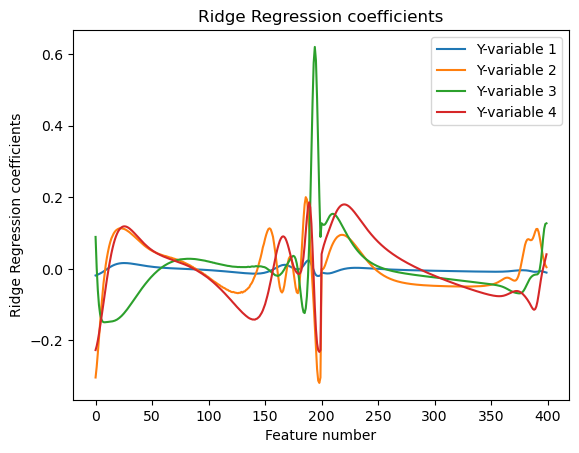

In [32]:
# Plotting the selected features
InRidge=np.zeros((1,X.shape[1]), dtype=int)[0]
InRidge[selected_Ridge]=1

fig, ax=plt.subplots()
plt.bar(range(0,X.shape[1]),InRidge)
plt.title('Ridge Regression')
plt.xlabel('Feature number')
plt.show()

# Plotting the resulting regression coefficients
fig, ax=plt.subplots()
plt.plot(range(0,X.shape[1]),B_Ridge.transpose())
plt.title('Ridge Regression coefficients')
ax.legend(['Y-variable 1', 'Y-variable 2', 'Y-variable 3', 'Y-variable 4'])
plt.xlabel('Feature number')
plt.ylabel('Ridge Regression coefficients')
plt.show()

## Embedded methods: LASSO


In [33]:
from sklearn.linear_model import Lasso

lasso=Lasso()
lasso_params = {'alpha': [1,0.1,0.01,0.001,0.0001,0] , 
                'max_iter': [10, 100, 1000, 10000], 
                }

gs_random = GridSearchCV(estimator=lasso, param_grid=lasso_params, cv=10)

start = time.time()

gs_random.fit(X_train_std, Y_train_std)

lasso = Lasso(**gs_random.best_params_)
lasso.fit(X_train_std, Y_train_std)
Y_pred_train  = lasso.predict(X_train_std)
Y_pred_test  = lasso.predict(X_test_std)

B_Lasso=lasso.coef_
mse_Lasso=mean_squared_error(Y_pred_test, Y_test_std)

selected=[]
for i in range(0,Y.shape[1]):
    sel=np.where(abs(B_Lasso[i,:])>0)
    selected=np.append(selected,sel)   
                 
selected=np.unique(selected)
selected_Lasso = [int(i) for i in selected]
                 
end = time.time()
time_used_Lasso=end - start

In [34]:
print('MSE: {0:.4f}'.format(mse_Lasso))
print('Number of features selected: '+str(len(selected_Lasso)))
print('Elapsed time (s): {0:.2f}'.format(time_used_Lasso))

MSE: 0.2453
Number of features selected: 187
Elapsed time (s): 69.03


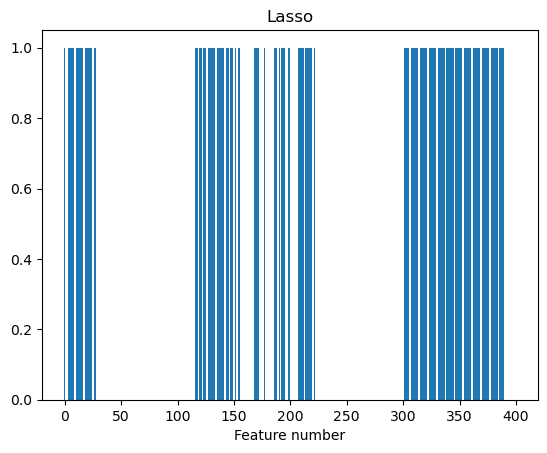

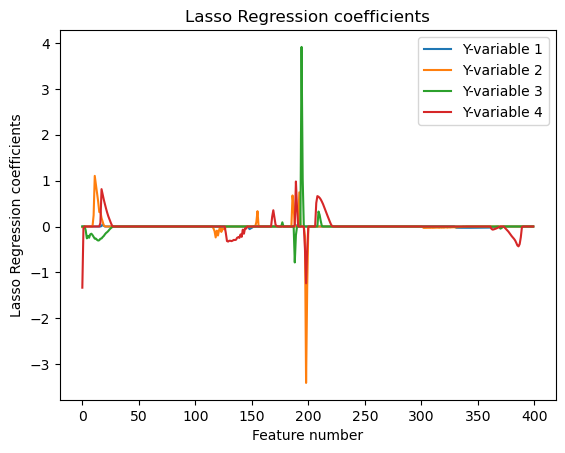

In [35]:
# Plotting the selected features
InLasso=np.zeros((1,X.shape[1]), dtype=int)[0]
InLasso[selected_Lasso]=1

fig, ax=plt.subplots()
plt.bar(range(0,X.shape[1]),InLasso)
plt.title('Lasso')
plt.xlabel('Feature number')
plt.show()

# Plotting the resulting regression coefficients
fig, ax=plt.subplots()
plt.plot(range(0,X.shape[1]),B_Lasso.transpose())
plt.title('Lasso Regression coefficients')
ax.legend(['Y-variable 1', 'Y-variable 2', 'Y-variable 3', 'Y-variable 4'])
plt.xlabel('Feature number')
plt.ylabel('Lasso Regression coefficients')
plt.show()

## Embedded methods: Elastic Net 

In [36]:
from sklearn.linear_model import ElasticNet

elnet=ElasticNet()
elnet_params = {'alpha': [0.01,0.001,0.0001,0], 
                'l1_ratio':[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95],
                'max_iter': [10, 100, 1000], 
                }

gs_random = GridSearchCV(estimator=elnet, param_grid=elnet_params, cv=10)

start = time.time()

gs_random.fit(X_train_std, Y_train_std)

elnet = ElasticNet(**gs_random.best_params_)

elnet.fit(X_train_std, Y_train_std)
Y_pred_train = elnet.predict(X_train_std)
Y_pred_test = elnet.predict(X_test_std)

B_Elnet=elnet.coef_
mse_Elnet=mean_squared_error(Y_pred_test, Y_test_std)

selected=[]
for i in range(0,Y.shape[1]):
    sel=np.where(abs(B_Elnet[i,:])>0)
    selected=np.append(selected,sel)   
                 
selected=np.unique(selected)
selected_Elnet = [int(i) for i in selected]
                 
end = time.time()
time_used_Elnet=end - start

In [37]:
print('MSE: {0:.4f}'.format(mse_Elnet))
print('Number of features selected: '+str(len(selected_Elnet)))
print('Elapsed time (s): {0:.2f}'.format(time_used_Elnet))

MSE: 0.2588
Number of features selected: 386
Elapsed time (s): 46.47


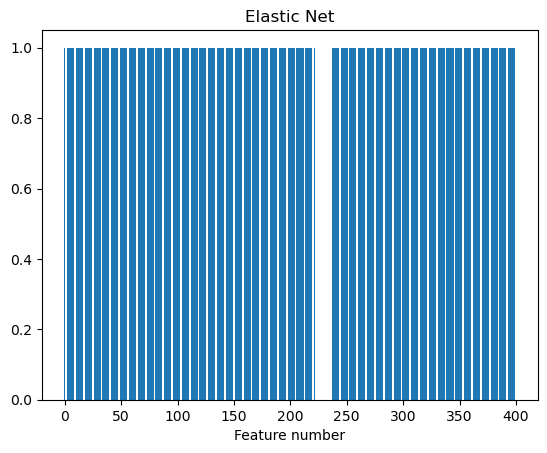

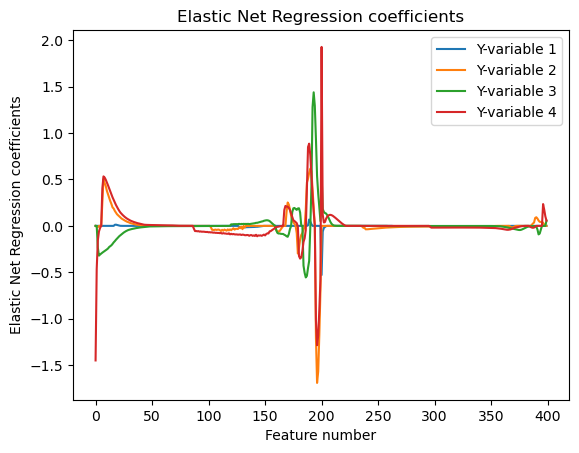

In [38]:
# Plotting the selected features
InElnet=np.zeros((1,X.shape[1]), dtype=int)[0]
InElnet[selected_Elnet]=1

fig, ax=plt.subplots()
plt.bar(range(0,X.shape[1]),InElnet)
plt.title('Elastic Net')
plt.xlabel('Feature number')
plt.show()

# Plotting the resulting regression coefficients
fig, ax=plt.subplots()
plt.plot(range(0,X.shape[1]),B_Elnet.transpose())
plt.title('Elastic Net Regression coefficients')
ax.legend(['Y-variable 1', 'Y-variable 2', 'Y-variable 3', 'Y-variable 4'])
plt.xlabel('Feature number')
plt.ylabel('Elastic Net Regression coefficients')
plt.show()

## Wrapper methods: Forward Selection

In [39]:
from sklearn.feature_selection import SequentialFeatureSelector
pls = PLSRegression(scale=False, n_components=1)

start = time.time()
sfs = SequentialFeatureSelector(pls, n_features_to_select='auto', direction='forward')
sfs.fit(X_train_std, Y_train_std)
selected_fs=np.where(sfs.get_support()==True)[0]

# Fit a PLSR model with the selected features     
pls_params = {'n_components': range(0,21)} #Testing from 1 to 20 PCs
gs_random = GridSearchCV(estimator=pls, param_grid=pls_params, cv=10)
gs_random.fit(X_train_std[:,selected_fs], Y_train_std)

pls = PLSRegression(**gs_random.best_params_, scale=False)
pls.fit(X_train_std[:,selected_fs], Y_train_std)
Y_pred_train = pls.predict(X_train_std[:,selected_fs])
Y_pred_test = pls.predict(X_test_std[:,selected_fs])
    
BPLSR_fs=pls.coef_
mse_fs=mean_squared_error(Y_pred_test, Y_test_std)

end = time.time()
time_used_fs=end - start

In [40]:
print('MSE: {0:.4f}'.format(mse_fs))
print('Number of PCs: '+str(gs_random.best_params_))
print('Number of features selected: '+str(len(selected_fs)))
print('Elapsed time (s): {0:.2f}'.format(time_used_fs))

MSE: 0.3113
Number of PCs: {'n_components': 12}
Number of features selected: 200
Elapsed time (s): 174.80


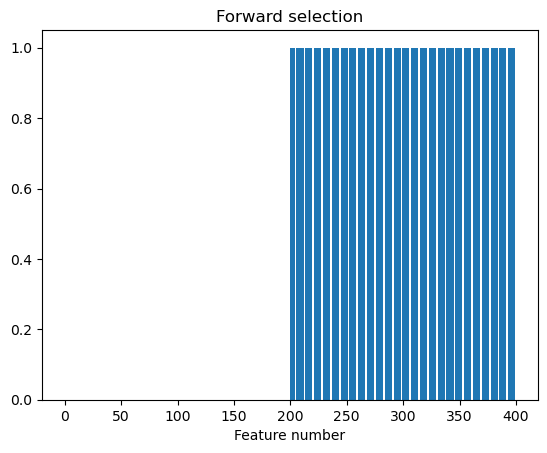

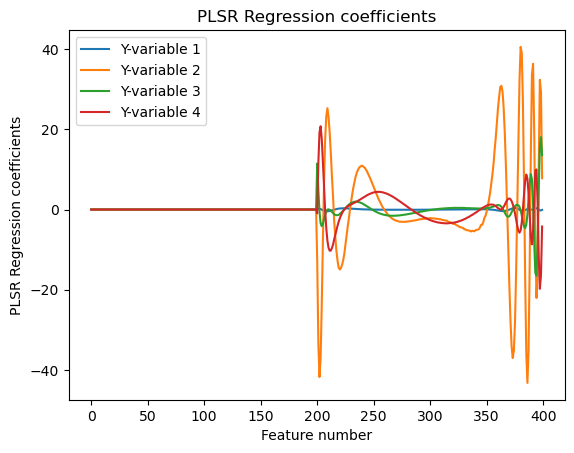

In [41]:
# Plotting the selected features
InFS=np.zeros((1,X.shape[1]), dtype=int)[0]
InFS[selected_fs]=1

fig, ax=plt.subplots()
plt.bar(range(0,X.shape[1]),InFS)
plt.title('Forward selection')
plt.xlabel('Feature number')
plt.show()

# Plotting the resulting PLSR regression coefficients

B_fs=np.zeros((X.shape[1],4))
BPLSR_fs=BPLSR_fs.transpose()

i=0
for j in selected_fs: 
        B_fs[j,:]=BPLSR_fs[i,:]
        i=i+1
        
fig, ax=plt.subplots()
plt.plot(range(0,X.shape[1]),B_fs)
plt.title('PLSR Regression coefficients')
ax.legend(['Y-variable 1', 'Y-variable 2', 'Y-variable 3', 'Y-variable 4'])
plt.xlabel('Feature number')
plt.ylabel('PLSR Regression coefficients')
plt.show()

## Wrapper methods: Backwards Elimination

In [42]:
pls = PLSRegression(scale=False)

start = time.time()
sfs = SequentialFeatureSelector(pls, n_features_to_select='auto', direction='backward')
sfs.fit(X_train_std, Y_train_std)
selected_be=np.where(sfs.get_support()==True)[0]

# Fit a PLSR model with the selected features     
pls_params = {'n_components': range(0,21)} #Testing from 1 to 20 PCs
gs_random = GridSearchCV(estimator=pls, param_grid=pls_params, cv=10)
gs_random.fit(X_train_std[:,selected_be], Y_train_std)

pls = PLSRegression(**gs_random.best_params_, scale=False)
pls.fit(X_train_std[:,selected_be], Y_train_std)
Y_pred_train = pls.predict(X_train_std[:,selected_be])
Y_pred_test = pls.predict(X_test_std[:,selected_be])

BPLSR_be=pls.coef_
mse_be=mean_squared_error(Y_pred_test, Y_test_std)

end = time.time()
time_used_be=end - start

In [43]:
print('MSE: {0:.4f}'.format(mse_be))
print('Number of PCs: '+str(gs_random.best_params_))
print('Number of features selected: '+str(len(selected_be)))
print('Elapsed time (s): {0:.2f}'.format(time_used_be))

MSE: 0.2888
Number of PCs: {'n_components': 12}
Number of features selected: 200
Elapsed time (s): 294.66


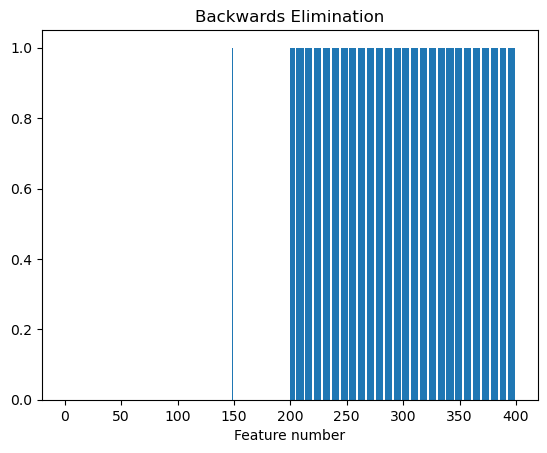

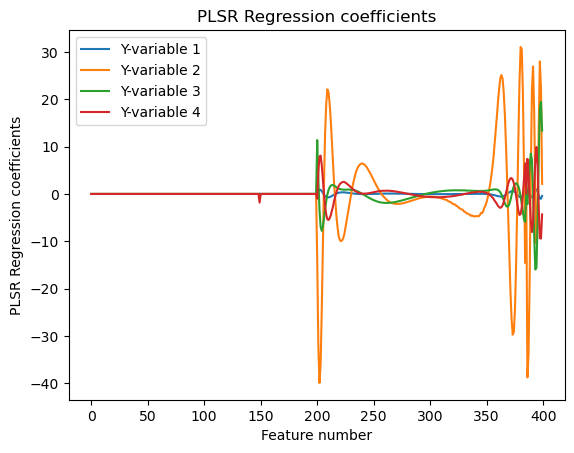

In [44]:
# Plotting the selected features
InBE=np.zeros((1,X.shape[1]), dtype=int)[0]
InBE[selected_be]=1

fig, ax=plt.subplots()
plt.bar(range(0,X.shape[1]),InBE)
plt.title('Backwards Elimination')
plt.xlabel('Feature number')
plt.show()

# Plotting the resulting PLSR regression coefficients

B_be=np.zeros((X.shape[1],4))
BPLSR_be=BPLSR_be.transpose()

i=0
for j in selected_be: 
        B_be[j,:]=BPLSR_be[i,:]
        i=i+1
        
fig, ax=plt.subplots()
plt.plot(range(0,X.shape[1]),B_be)
plt.title('PLSR Regression coefficients')
ax.legend(['Y-variable 1', 'Y-variable 2', 'Y-variable 3', 'Y-variable 4'])
plt.xlabel('Feature number')
plt.ylabel('PLSR Regression coefficients')
plt.show()

## Final comparison of the feature selection methods

([<matplotlib.axis.XTick at 0x7011acdbd0>,
 [Text(0, 0, 'Filtering'),
  Text(1, 0, 'Ridge Regression'),
  Text(2, 0, 'LASSO'),
  Text(3, 0, 'Elastic net'),
  Text(4, 0, 'Forward Selection'),
  Text(5, 0, 'Backwards Elimination')])

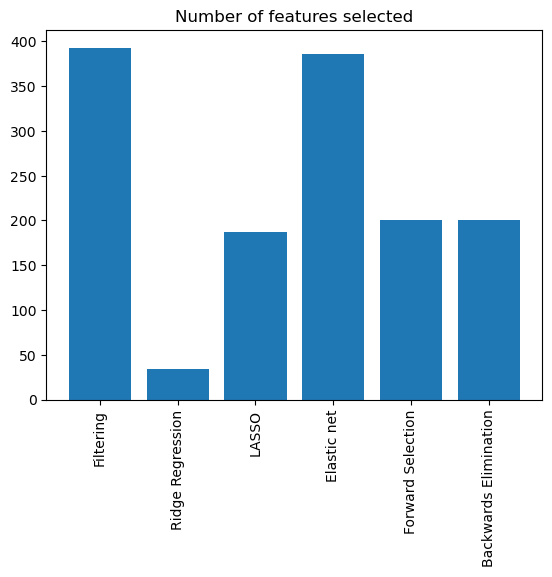

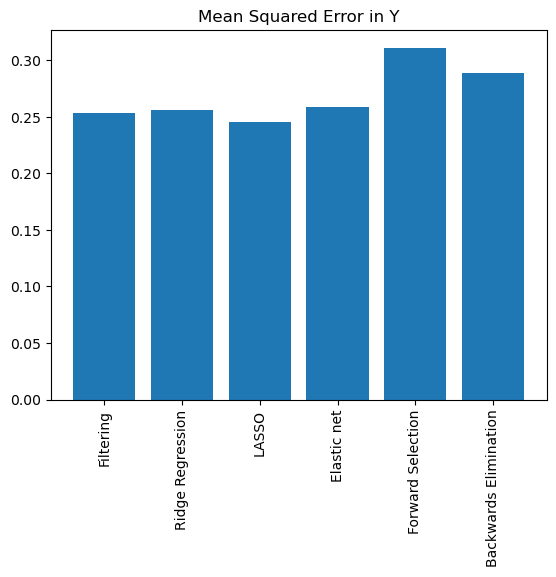

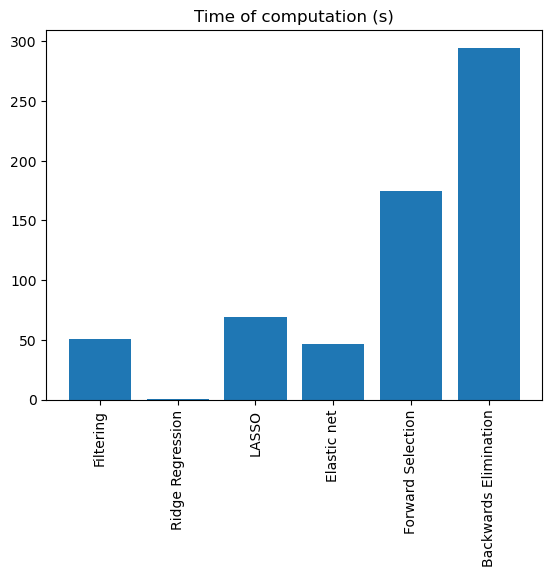

In [45]:
# Number of features selected
nF=len(selected_f)
nFS=len(selected_fs)
nBE=len(selected_be)
nRidge=len(selected_Ridge)
nLasso=len(selected_Lasso)
nElnet=len(selected_Elnet)

fig, ax=plt.subplots()
plt.bar(range(0,6),[nF, nRidge, nLasso, nElnet, nFS, nBE])
plt.title('Number of features selected')
plt.xticks(range(0,6), ['Filtering', 'Ridge Regression', 'LASSO', 'Elastic net', 'Forward Selection', 'Backwards Elimination'], rotation='vertical')

# Prediction accuracy
fig, ax=plt.subplots()
plt.bar(range(0,6),[mse_f, mse_Ridge, mse_Lasso, mse_Elnet, mse_fs, mse_be])
plt.title('Mean Squared Error in Y')
plt.xticks(range(0,6), ['Filtering', 'Ridge Regression', 'LASSO', 'Elastic net', 'Forward Selection', 'Backwards Elimination'], rotation='vertical')

# Time of computation
fig, ax=plt.subplots()
plt.bar(range(0,6),[time_used_f, time_used_Ridge, time_used_Lasso, time_used_Elnet, time_used_fs, time_used_be])
plt.title('Time of computation (s)')
plt.xticks(range(0,6), ['Filtering', 'Ridge Regression', 'LASSO', 'Elastic net', 'Forward Selection', 'Backwards Elimination'], rotation='vertical')
